# 04. GBDT 가설 시험: 나무 개수와 학습률

02의 GBDT 설정(나무 600개, 학습률 0.05)은 튜닝한 값이 아니라 흔히 쓰는 출발값이에요. 두 가지 가설만 시험해서 근거 있는 값으로 바꿔요.

| # | 가설 | 근거 |
|---|---|---|
| H1 | 나무 개수를 늘리면 오차가 줄어든다 | 02에서 일찍 멈추기를 켰는데도 5개 fold 모두 상한 600개를 다 씀(02 노트북 GBDT 셀의 `나무 600개` 출력) → 아직 덜 배운 상태 |
| H2 | 학습률을 낮추고 나무를 늘리면 더 좋아진다 | 나무 하나가 고치는 폭이 작을수록 꼼꼼하게 맞춤 (대신 나무가 더 필요) |

### 시험 방법
- 학습률 3가지(0.1, 0.05, 0.02)로 나무를 2,000개까지 쌓으면서, **나무가 하나 늘 때마다** 검증 오차(MAE)를 기록해요. 곡선이 평평해지는 곳이 필요한 나무 개수예요.
- 나머지 설정(잎 31개, 잎 최소 데이터 40, L2 1.0)은 02와 같아요. 한 번에 하나씩만 바꿔야 어떤 값 때문인지 알 수 있어요.
- **고르는 데이터와 평가 데이터를 나눠요.** 평가 점수를 보고 값을 고르면 그 점수가 부풀기 때문이에요.

| 데이터 | 코일 | 쓰임 |
|---|---|---|
| 학습 | fold 0~3의 75% (전체의 60%) | 곡선 그릴 때 학습 |
| 검증 | fold 0~3의 25% (전체의 20%) | 곡선 그리기 → **값 고르기** |
| 최종 평가 | fold 4 (전체의 20%) | 마지막에 **한 번만**: 02 설정 vs 고른 설정 |

전체 실행에 **2~3분** 걸려요(대부분 곡선 그리기).

## 0. 준비

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error

installed = {f.name for f in font_manager.fontManager.ttflist}
for font in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:
    if font in installed:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlesize": 12,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})

# 데이터: pjh 정리 기준 (01·02와 같음)
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pjh/data_utils.py").exists())
sys.dont_write_bytecode = True   # 다른 팀원 폴더에 캐시(__pycache__)를 만들지 않음
sys.path.insert(0, str(REPO / "pjh"))
sys.path.insert(0, str(REPO / "kdh/src"))
from data_utils import load_clean                     # pjh 데이터 정리 기준 (팀 공통)
from prepare_data import COLS, add_features           # kdh 열 이름·파생 변수

clean, clean_info = load_clean()                      # 스탠드 누락·두께 불연속·폭 변동 코일 제외
df = add_features(clean.rename(columns=COLS))
df["chain_ok"] = True                                 # 정리 후 남은 코일은 모두 연속

V1, HO1 = 1096.0, 27.7

def add_physics(d):
    d = d.copy()
    d["dh"] = d["h_in"] - d["h_out"]
    d["reduction"] = d["dh"] / d["h_in"]
    d["L"] = np.sqrt(d["R"] * d["dh"])
    d["strain"] = np.log(d["h_in"] / d["h_out"])
    d["v"] = V1 * HO1 / d["h_out"]
    d["strain_rate"] = d["strain"] * d["v"] / d["L"]
    return d

df = add_physics(df)

# 단조성 점검용: 압하량 5% 더 누른 가상 데이터 (02와 같음)
df_more = df.copy()
df_more["h_out"] = df["h_out"] - 0.05 * df["dh"]
df_more = add_physics(df_more)

# 01·02와 같은 코일 단위 5-fold
df["fold"] = -1
for k, (_, test_idx) in enumerate(GroupKFold(n_splits=5).split(df, groups=df["coil"])):
    df.loc[df.index[test_idx], "fold"] = k

NUM = ["stand_no", "h_in", "h_out", "W", "R", "T_K", "reduction", "dh", "L", "strain", "strain_rate"]
FEATURES = ["grade"] + NUM
GRADES = sorted(df["grade"].unique())

def tree_input(d):
    X = d[FEATURES].copy()
    X["grade"] = pd.Categorical(X["grade"], categories=GRADES)
    return X

### 데이터 나누기

In [2]:
dev = df[df["fold"] != 4]     # 값 고르기용 (80%)
test = df[df["fold"] == 4]    # 최종 평가용 (20%), 마지막까지 손대지 않음

tr_idx, va_idx = next(GroupKFold(n_splits=4).split(dev, groups=dev["coil"]))
train, valid = dev.iloc[tr_idx], dev.iloc[va_idx]

split_view = pd.DataFrame({
    "코일 수": [train["coil"].nunique(), valid["coil"].nunique(), test["coil"].nunique()],
    "행 수": [len(train), len(valid), len(test)],
}, index=["학습", "검증", "최종 평가"])
display(split_view)
assert not set(train["coil"]) & set(valid["coil"]) and not set(dev["coil"]) & set(test["coil"])

,코일 수,행 수
학습,4520,22600
검증,1507,7535
최종 평가,1506,7530


## 1. 나무 개수와 학습률에 따른 검증 오차 곡선

`staged_predict`는 나무를 1개, 2개, … 쌓았을 때의 예측을 차례로 돌려줘요. 그래서 학습 한 번으로 나무 개수별 오차를 다 볼 수 있어요.

학습률 0.1: 12초
학습률 0.05: 12초
학습률 0.02: 14초


,나무 600개 MAE,최저 MAE,최저일 때 나무 수,최저+1% 안에 든 나무 수,2000개 학습 시간 (초)
학습률,,,,,
0.100000,0.444,0.419,1981,1427,12
0.050000,0.468,0.426,1998,1646,12
0.020000,0.525,0.452,2000,1825,14


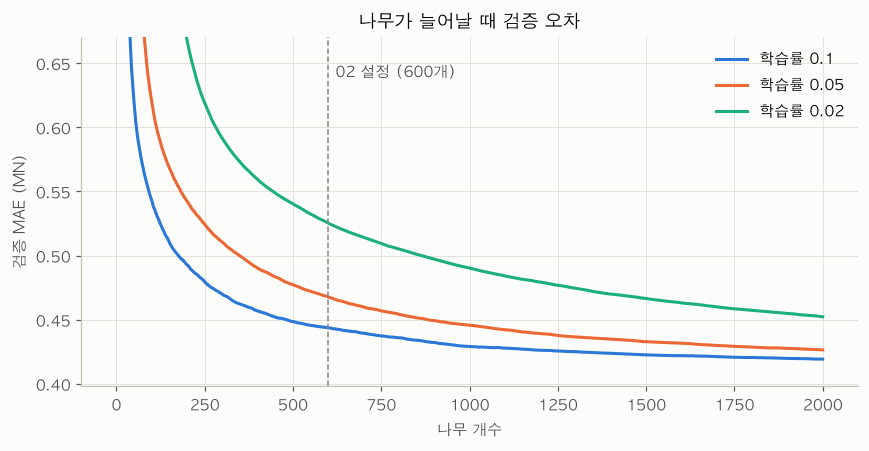

In [3]:
MAX_TREES = 2000
BASE = dict(max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1.0, early_stopping=False)

curves, fit_secs = {}, {}
for lr in [0.1, 0.05, 0.02]:
    start = time.time()
    model = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=0,
                                          learning_rate=lr, max_iter=MAX_TREES, **BASE)
    model.fit(tree_input(train), train["F_MN"])
    fit_secs[lr] = time.time() - start
    curves[lr] = np.array([mean_absolute_error(valid["F_MN"], p) for p in model.staged_predict(tree_input(valid))])
    print(f"학습률 {lr}: {fit_secs[lr]:.0f}초")

rows = []
for lr, c in curves.items():
    near = int(np.argmax(c <= c.min() * 1.01))   # 최저 MAE의 1% 안에 처음 들어온 위치
    rows.append({"학습률": lr, "나무 600개 MAE": c[599], "최저 MAE": c.min(), "최저일 때 나무 수": int(c.argmin()) + 1,
                 "최저+1% 안에 든 나무 수": near + 1, f"{MAX_TREES}개 학습 시간 (초)": fit_secs[lr]})
curve_table = pd.DataFrame(rows).set_index("학습률")
display(curve_table.style.format({"나무 600개 MAE": "{:.3f}", "최저 MAE": "{:.3f}", f"{MAX_TREES}개 학습 시간 (초)": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4.2))
for (lr, c), color in zip(curves.items(), [BLUE, ORANGE, AQUA]):
    ax.plot(np.arange(1, len(c) + 1), c, color=color, linewidth=2, label=f"학습률 {lr}")
low = min(c.min() for c in curves.values())
ax.axvline(600, color="#898781", linestyle="--", linewidth=1)
ax.text(620, low * 1.55, "02 설정 (600개)", color="#52514e", va="top")
ax.set_ylim(low * 0.95, low * 1.6)
ax.set_xlabel("나무 개수")
ax.set_ylabel("검증 MAE (MN)")
ax.set_title("나무가 늘어날 때 검증 오차")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 읽는 법
- **H1 확인:** 학습률 0.05(02 설정) 곡선이 600개(점선) 뒤로도 계속 내려가면 H1이 맞아요.
- **H2 확인:** 같은 나무 개수에서 학습률 0.02 곡선이 0.1보다 낮으면 H2가 맞고, 높으면 틀려요.
- **나무 개수 고르기:** 곡선이 평평해진 뒤로는 나무를 더 쌓아도 오차는 거의 그대로이고 시간만 늘어요. 그래서 "최저 MAE의 1% 안에 처음 들어온 나무 수"를 써요.

## 2. 설정 고르기

최저 MAE가 가장 낮은 학습률을 고르고, 나무 개수는 그 학습률의 "최저+1% 안에 든 나무 수"를 100 단위로 올려서 써요. 표를 보고 자동으로 정해요.

In [4]:
best_lr = curve_table["최저 MAE"].idxmin()
best_trees = int(np.ceil(curve_table.loc[best_lr, "최저+1% 안에 든 나무 수"] / 100) * 100)
CHOSEN = dict(learning_rate=best_lr, max_iter=best_trees, **BASE)
print(f"고른 설정: 학습률 {best_lr}, 나무 {best_trees}개")

고른 설정: 학습률 0.1, 나무 1500개


## 3. 최종 평가: 02 설정 vs 고른 설정

두 설정을 fold 0~3 전체로 학습하고, 지금까지 손대지 않은 **fold 4**로 한 번만 평가해요.
- **더 누르면 하중 감소 (%)**: 압하량을 5% 더 눌렀는데 예측 하중이 오히려 줄어든 행의 비율이에요. 물리적으로는 0%여야 해요. 다음 단계(단조 제약)에서 고칠 문제라 여기서는 기록만 해요.
- **1만 행 예측 시간**: 최적화에서 모델을 수천 번 부르므로 속도도 봐요.

In [5]:
FINAL = {
    "02 설정": dict(max_iter=600, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
                    l2_regularization=1.0, early_stopping=True, n_iter_no_change=30),
    "고른 설정": CHOSEN,
}
sample = tree_input(test.sample(10_000, replace=True, random_state=0))
rows = []
for name, params in FINAL.items():
    start = time.time()
    model = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=0, **params).fit(tree_input(dev), dev["F_MN"])
    fit_sec = time.time() - start
    p = model.predict(tree_input(test))
    p_more = model.predict(tree_input(df_more.loc[test.index]))
    start = time.time()
    model.predict(sample)
    rows.append({"설정": name, "나무 수": model.n_iter_, "최종 MAE": mean_absolute_error(test["F_MN"], p),
                 "최종 R²": r2_score(test["F_MN"], p),
                 "평균 오차율 (%)": ((p - test["F_MN"]).abs() / test["F_MN"]).mean() * 100,
                 "더 누르면 하중 감소 (%)": (p_more < p - 1e-9).mean() * 100,
                 "학습 시간 (초)": fit_sec, "1만 행 예측 (초)": time.time() - start})
final_table = pd.DataFrame(rows).set_index("설정")
display(final_table.style.format({"최종 MAE": "{:.3f}", "최종 R²": "{:.4f}", "평균 오차율 (%)": "{:.2f}",
                                  "더 누르면 하중 감소 (%)": "{:.1f}", "학습 시간 (초)": "{:.0f}", "1만 행 예측 (초)": "{:.2f}"}))

,나무 수,최종 MAE,최종 R²,평균 오차율 (%),더 누르면 하중 감소 (%),학습 시간 (초),1만 행 예측 (초)
설정,,,,,,,
02 설정,600,0.460,0.9918,2.58,5.5,6,0.07
고른 설정,1500,0.396,0.9934,2.21,7.5,12,0.16


## 정리 (실행 후 직접 채우기)

| 가설 | 맞음 / 틀림 | 근거 숫자 |
|---|---|---|
| H1 나무 개수를 늘리면 좋아진다 | | |
| H2 학습률을 낮추면 좋아진다 | | |

- 고른 설정: 학습률 ___, 나무 ___개
- 최종 평가 MAE: 02 설정 ___ → 고른 설정 ___